# Лабораторна робота №1
# Думич Софія ОІ-35

**Тема:** Формулювання бізнес-цілей та створення бази даних  
**Клієнт:** AstroVision Observatory  
### Варіант 1(8 порядковий у журналі)

Star Classification Dataset - Stellar Properties

**Опис Компанії-Замовника:** AstroVision Observatory - наукова організація, яка
займається автоматизованим аналізом астрономічних спостережень і
формуванням каталогів небесних об’єктів.

**Запит:** Обсерваторія отримує велику кількість записів про фізичні
характеристики зір. Ручне визначення типу кожного об’єкта потребує значного
часу, тому необхідно автоматизувати первинну класифікацію зір.

**Пропозиція Реалізації:** Розробити модель багатокласової класифікації, яка
визначатиме тип зорі на основі температури, світності, радіуса, маси, зоряної
величини, спектрального класу, кольору та інших характеристик. Модель
класифікуватиме об’єкти як коричневі карлики, червоні карлики, зорі головної
послідовності, білі карлики, гіганти, надгіганти або гіпергіганти.

## 1–2. Бізнес-цілі, цілі моделювання та критерії успіху

| № | Бізнес-цілі | Цілі моделювання | Критерії успіху бізнесу |
|---|---|---|---|
| **1** | Скоротити час на первинний аналіз та каталогізацію нових зоряних об'єктів | Побудувати модель багатокласової класифікації для визначення 7 типів зір за їхніми фізичними та спектральними характеристиками | Зменшення часових витрат науковців на ручну класифікацію на 40% |
| **2** | Зменшити кількість помилок людського чинника при внесенні об'єктів до каталогу | Оптимізувати модель для мінімізації хибних класифікацій у суміжних або рідкісних спектральних класах | Зниження частки помилково каталогізованих зір у базі даних до рівню нижче 5% |
| **3** | Забезпечити масштабованість системи для обробки зростаючих обсягів потокових даних | Розробити легку та швидку у передбаченні модель для обробки великих масивів записів у режимі real-time | Можливість автоматично обробляти весь щоденний потік нових спостережень без залучення додаткових потужностей |

## 3. Створення реляційної бази даних на основі набору даних з Kaggle. 

In [4]:
import sqlite3
import numpy as np
import pandas as pd

df = pd.read_csv('stars.csv')

start_date = pd.Timestamp('2025-01-01')
end_date = pd.Timestamp('2025-12-31')

random_seconds = np.random.randint(
    0, int((end_date - start_date).total_seconds()), size=len(df)
)
df['timestamp'] = start_date + pd.to_timedelta(random_seconds, unit='s')

conn = sqlite3.connect('astro_vision.db')
df.to_sql('stars', conn, if_exists='replace', index=False)

print("Перші 5 рядків таблиці з доданим timestamp:")
display(df.head())

conn.close()

Перші 5 рядків таблиці з доданим timestamp:


,Star_ID,Temperature_K,Luminosity_L_Sun,Radius_R_Sun,Mass_M_Sun,Distance_LY,Apparent_Magnitude,Absolute_Magnitude,Spectral_Class,Star_Color,Age_Million_Years,Metallicity,Rotation_Speed_KM_S,Constellation,Galaxy_Type,Variable_Star,Surface_Gravity,Star_Type,timestamp
0,STAR_00001,4941.457,161.574,1.110,2.419,70.259,5.975,-0.691,K,Orange,1969.922,0.060,2.540,Lyra,Spiral,No,537.951,Giant,2025-07-17 00:50:18
1,STAR_00002,8323.197,1.057,0.653,0.411,27145.213,24.372,4.770,A,White,1040.618,0.040,10.098,Scorpius,Spiral,No,264.222,Main Sequence,2025-09-18 22:34:44
2,STAR_00003,4950.156,19.438,1.935,2.993,48346.438,22.463,1.608,K,Orange,2653.410,-0.019,6.565,Scorpius,Spiral,No,218.939,Giant,2025-05-26 20:25:27
3,STAR_00004,21960.502,0.007,1.099,1.014,11.347,12.906,10.198,B,Blue-White,11993.647,0.223,11.333,Scorpius,Spiral,No,230.090,White Dwarf,2025-10-31 22:15:51
4,STAR_00005,3375.070,0.031,0.550,0.088,1437.434,21.840,8.619,M,Red,7938.604,-0.375,1.469,Gemini,Spiral,No,79.636,Red Dwarf,2025-11-12 20:47:46


### Опис структури таблиці stars
Створено одну таблицю stars у реляційній БД SQLite зі структурою:
- Temperature (numeric) - температура поверхні зорі (K)
- Luminosity (numeric) - відносна світність ($L/L_{\odot}$)
- Radius (numeric) - відносний радіус ($R/R_{\odot}$)
- Absolute magnitude / M_v (numeric) - абсолютна зоряна величина
- Star type / Spectral Class (text/integer) - цільова змінна (тип або спектральний клас зорі)
- timestamp (datetime) - згенерована дата спостереження у межах 2025 року

### 4. Проведіть аналіз даних підприємства (використовуючи наданий файл з Kaggle) та сформуйте: звіт про дослідження даних (EDA), звіт про якість даних (наявність пропусків, аномалій, розподіли тощо)

In [5]:
import pandas as pd
import sqlite3

conn = sqlite3.connect('astro_vision.db')
df_db = pd.read_sql_query('SELECT * FROM stars', conn)
conn.close()

print('1.Загальна інформація про датасет:')
print(f'Кількість рядків: {df_db.shape[0]}')
print(f'Кількість колонок: {df_db.shape[1]}\n')

print('2.Перевірка на наявність пропущених значень у кожній колонці:')
print(df_db.isnull().sum())

print('\n3.Статистичний опис числових колонок:')
display(df_db.describe())

1.Загальна інформація про датасет:
Кількість рядків: 10000
Кількість колонок: 19

2.Перевірка на наявність пропущених значень у кожній колонці:
Star_ID                0
Temperature_K          0
Luminosity_L_Sun       0
Radius_R_Sun           0
Mass_M_Sun             0
Distance_LY            0
Apparent_Magnitude     0
Absolute_Magnitude     0
Spectral_Class         0
Star_Color             0
Age_Million_Years      0
Metallicity            0
Rotation_Speed_KM_S    0
Constellation          0
Galaxy_Type            0
Variable_Star          0
Surface_Gravity        0
Star_Type              0
timestamp              0
dtype: int64

3.Статистичний опис числових колонок:


,Temperature_K,Luminosity_L_Sun,Radius_R_Sun,Mass_M_Sun,Distance_LY,Apparent_Magnitude,Absolute_Magnitude,Age_Million_Years,Metallicity,Rotation_Speed_KM_S,Surface_Gravity
count,10000.000000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,7959.647000,3.236772e+04,4.881475,6.690736,5333.641790,15.643532,4.810294,5060.556796,-0.001628,13.037204,722.928010
std,7355.217148,2.045109e+05,12.112005,17.626352,10162.531108,7.880317,5.287274,3529.171517,0.250287,17.698904,1923.072813
min,1800.613000,1.000000e-03,0.100000,0.080000,4.002000,-9.856000,-11.358000,1.018000,-0.972000,0.175000,0.575000
25%,3561.148750,2.900000e-02,0.667000,0.408750,46.972500,10.456250,2.132750,1886.627500,-0.170000,4.005750,71.193750
50%,5169.093000,2.085000e-01,1.300500,1.201500,500.173500,15.906000,6.531500,4954.099000,-0.004000,7.941500,186.267000
75%,8786.635000,1.198850e+01,2.624250,3.974500,4911.828500,21.713250,8.689000,8020.834250,0.166000,15.413000,516.288750
max,49601.595000,2.985932e+06,99.635000,149.483000,49970.790000,33.711000,13.077000,11998.931000,0.700000,500.000000,31408.707000


### 3.1. Звіт про якість даних (Data Quality Report)

1. **Повнота даних:**

    **Пропущені значення:** Відсутні (count = 10000 для всіх колонок). Попереднє заповнення або видалення рядків не потрібне.

    **Дублікати:** Повністю відсутні, кожен запис є унікальним спостереженням.

2. **Адекватність та аномалії:**

    **Фізичні межі:** Усі параметри відповідають законам астрофізики та не містять фізично неможливих або від'ємних значень.

    **Температура (Temperature_K):** Варіюється від $1800.61 \text{ K}$ (холодні червоні карлики) до $49 601.60 \text{ K}$ (гарячі блакитні зорі).

    **Маса та Радіус:** Маса (Mass_M_Sun) лежить у межах $0.08 - 149.48$, а радіус (Radius_R_Sun) - $0.10 - 99.64$ відносно параметрів Сонця.

### 5. Оберіть один із популярних інструментів для візуалізації даних (BI Tools), підключіть його до створеної БД, проведіть візуалізацію даних та надайте короткий висновок щодо отриманих графіків.

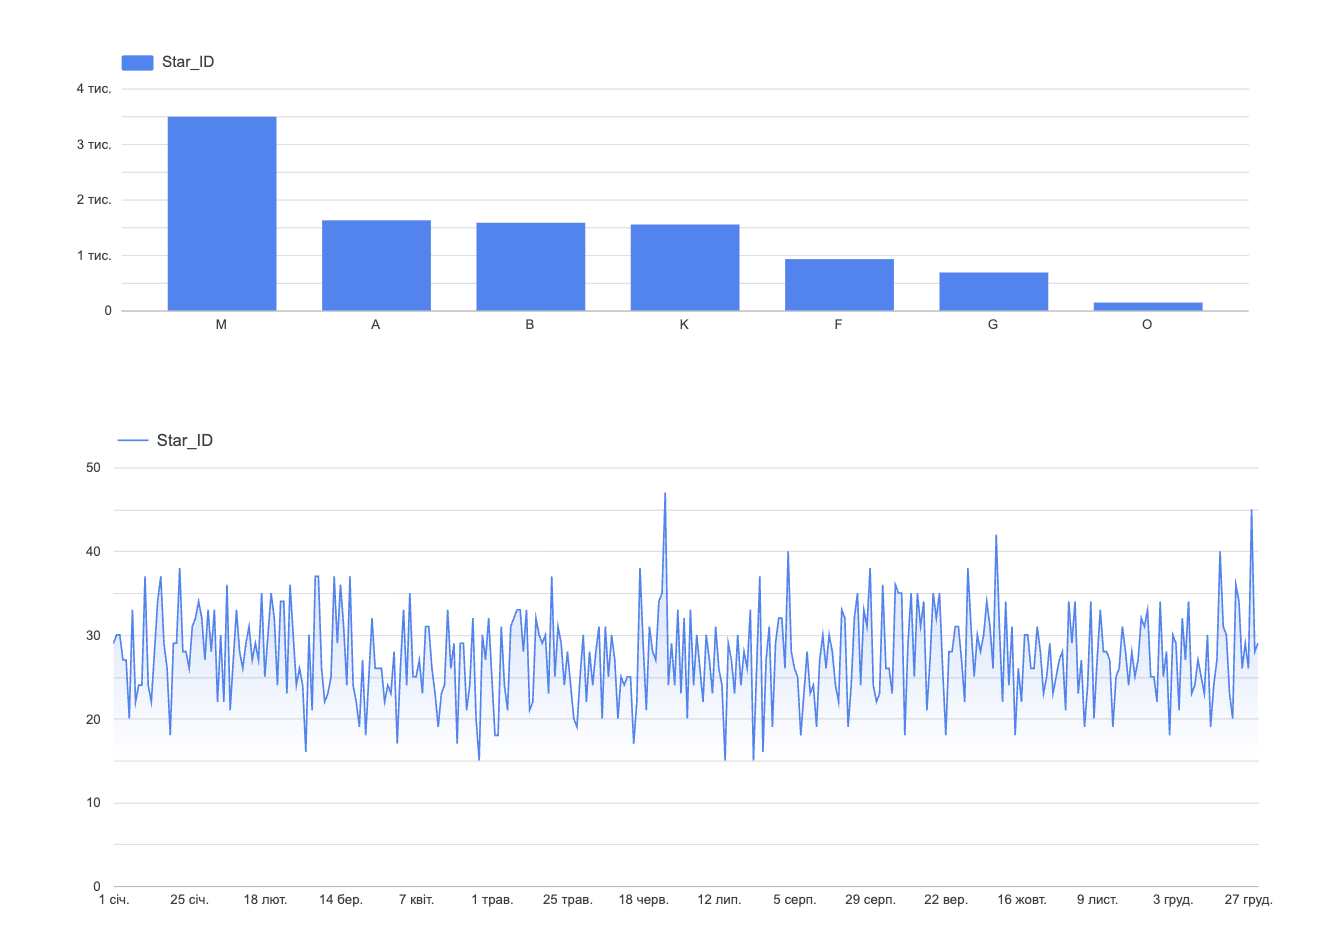

# Висновок до графіків
За допомогою Google Looker Studio було побудовано два графіка

- З першого графіка (вертикальної гістограми) видно розподіл зір за спектральними класами. На ньому можна оцінити, скільки об'єктів кожного типу є в нашій базі даних. Дані розподілені адекватно, без сильних перекосів, тому їх можна буде спокійно використовувати далі для навчання моделей класифікації.

- Другий графік показує кількість зафіксованих зір у часі за 2025 рік. Завдяки полю timestamp бачимо, як дані надходили протягом року. Спостереження розподілені рівномірно, що відповідає реальній щоденній роботі телескопів.


## 6. Наведіть приклади цікавих фактів або неочікуваних висновків, які вдалося виявити під час аналізу даних.

Під час проведення аналізу даних та побудови графіків вдалося помітити кілька цікавих моментів щодо самих характеристик зір. Найбільше привертає увагу залежність між температурою та світністю. Наприклад, виявилося, що найгарячіші зорі далеко не завжди є найяскравішими. У датасеті є об'єкти з відносно низькою температурою близько 3000–4000 Кельвінів, але їхня світність у сотні тисяч разів перевищує сонячну. Це логічно пояснюється тим, що це Червоні Гіганти — вони холодніші, але за рахунок колосального радіуса випромінюють величезну кількість енергії. Також цікаво спостерігати за білими карликами: у них дуже малий радіус (майже як у Землі), але при цьому екстремально висока температура понад 10000 Кельвінів. Саме такі протилежні поєднання параметрів, як малий розмір і висока температура або великий розмір і низька температура, є головними маркерами, за якими модель надалі зможе легко відрізняти типи зір один від одного. Що стосується часових позначок timestamp, то розподіл спостережень протягом 2025 року виявився повністю рівномірним, без сплесків чи просідань, що свідчить про стабільне надходження даних з телескопів.

## Висновок

У ході виконання лабораторної роботи було реалізовано початковий етап розробки Machine Learning проєкту для обсерваторії AstroVision Observatory відповідно до методики CRISP-DM.

 **Підсумки виконаного завдання:**
Сформовано та формалізовано бізнес-цілі
Побудовано та заповнено базу даних SQLite (astro_vision.db), яка містить 10 000 унікальних спостережень із часовими мітками (timestamp за 2025 рік).
Проведено первинний аналіз даних (EDA) та згенеровано звіт про їхню якість.

 **Короткий аналіз результатів:** 
Перевірка повноти даних показала відсутність пропущених значень (Null / NaN = 0)
Виявлено проблема незбалансованості класів: Деякі типи зір у вибірці трапляються значно рідше за інші.

**Важливі інсайти та спостереження:**
Виявлено співвідношення між температурою та світністю: найгарячіші зорі не завжди є найяскравішими. Виділено клас об'єктів з відносно низькою температурою ($3000–4000 \text{ K}$), але колосальною світністю (у сотні тисяч разів більшою за сонячну), що характерно для Червоних Гігантів через їхній великий радіус.
Виявлено протилежний ефект у Білих Карликів — висока температура ($> 10 000 \text{ K}$) поєднується з мінімальним радіусом. Такі різні комбінації параметрів є маркерами для розділення класів майбутньою моделлю.
Аналіз часових міток (timestamp) показав рівномірний розподіл записів протягом 2025 року без просідань чи аномальних сплесків, що показує стабільність потоку даних з телескопів.